# MAP, Variational Inference, and MCMC on a Loss Surface

This notebook builds a schematic one-dimensional negative log posterior and uses it to compare MAP, variational inference, and MCMC.

In [8]:
import sys
from pathlib import Path

import warnings

import numpy as np
import matplotlib.pyplot as plt
try:
    import scienceplots
    HAS_SCIENCEPLOTS = True
except ModuleNotFoundError:
    HAS_SCIENCEPLOTS = False
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


def find_project_root(start):
    for base in [start, *start.parents]:
        for candidate in [base, base / "barrier-extraction"]:
            if (candidate / "src").is_dir() and (candidate / "data").is_dir():
                return candidate
    raise FileNotFoundError("Could not locate barrier-extraction project root containing src/ and data/.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
PLOT_DIR = PROJECT_ROOT / "plots"
PLOT_DIR.mkdir(exist_ok=True)

if HAS_SCIENCEPLOTS:
    plt.style.use(["science", "notebook", "ieee", "grid"])
else:
    warnings.warn("scienceplots is not installed; using Matplotlib defaults for this run.")
    plt.style.use("default")
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 16,
    "axes.titlesize": 17,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.2,
})


In [9]:
rng = np.random.default_rng(1848)

theta = np.linspace(-4.2, 4.2, 1800)


def gaussian(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2)


def trapz_compat(y, x):
    return np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x))


def neg_log_posterior(x):
    edge_wall = 0.22 * np.maximum(np.abs(x) - 3.55, 0.0) ** 4
    edge_wall = edge_wall + 0.03 * np.maximum(np.abs(x) - 3.90, 0.0) ** 6
    uneven_floor = 2.65 + edge_wall + 0.22 * np.sin(0.95 * x + 0.40) - 0.16 * np.sin(1.80 * x - 0.60)
    wells = (
        1.10 * gaussian(x, -3.25, 0.24)
        + 1.65 * gaussian(x, -2.28, 0.28)
        + 1.10 * gaussian(x, -1.25, 0.25)
        + 2.65 * gaussian(x, 0.22, 0.38)
        + 1.35 * gaussian(x, 1.32, 0.27)
        + 1.95 * gaussian(x, 2.42, 0.26)
        + 1.05 * gaussian(x, 3.25, 0.24)
    )
    corrugation = 0.14 * np.sin(4.6 * x + 0.25) + 0.06 * np.sin(8.0 * x)
    loss = uneven_floor - wells + corrugation
    return loss - loss.min() + 0.35


loss = neg_log_posterior(theta)
posterior = np.exp(-loss)
posterior = posterior / trapz_compat(posterior, theta)

d1 = np.gradient(loss, theta)
local_min_idx = np.where((d1[:-1] < 0.0) & (d1[1:] >= 0.0))[0] + 1
local_min_idx = local_min_idx[(theta[local_min_idx] > theta.min() + 0.15) & (theta[local_min_idx] < theta.max() - 0.15)]
min_theta = theta[local_min_idx]
min_loss = loss[local_min_idx]
min_weight = np.exp(-min_loss)
min_weight = min_weight / min_weight.max()

prior_variant_losses = []
for shift, tilt, width, amp in [(-0.18, -0.055, 2.8, 0.12), (0.12, 0.045, 3.2, -0.10), (0.02, -0.025, 2.2, 0.075), (0.24, 0.030, 3.7, 0.055)]:
    variant = neg_log_posterior(theta - shift) + tilt * theta + amp * gaussian(theta, 1.2, width)
    prior_variant_losses.append(variant - variant.min() + 0.35)

smooth_loss = np.convolve(loss, np.ones(101) / 101, mode="same")
flat_vi = np.full_like(theta, np.percentile(loss, 72))
vi_curves = [
    (0.00, flat_vi, r"$0$"),
    (0.25, 0.76 * flat_vi + 0.24 * smooth_loss + 0.20 * gaussian(theta, -0.3, 2.8), r"$1/4$"),
    (0.50, 0.54 * flat_vi + 0.46 * smooth_loss - 0.08 * gaussian(theta, 0.5, 1.4), r"$1/2$"),
    (0.75, 0.31 * flat_vi + 0.69 * smooth_loss - 0.14 * gaussian(theta, 0.45, 0.95), r"$3/4$"),
    (1.00, 0.14 * flat_vi + 0.86 * smooth_loss + 0.09 * np.sin(1.3 * theta + 0.2), r"$1$"),
]

mcmc_prob = posterior / posterior.sum()
mcmc_theta = rng.choice(theta, size=135, p=mcmc_prob)
mcmc_hist_theta = rng.choice(theta, size=1200, p=mcmc_prob)
mcmc_loss = neg_log_posterior(mcmc_theta)
mcmc_loss = mcmc_loss + 0.075 + np.abs(rng.normal(0.0, 0.030, size=mcmc_loss.size))


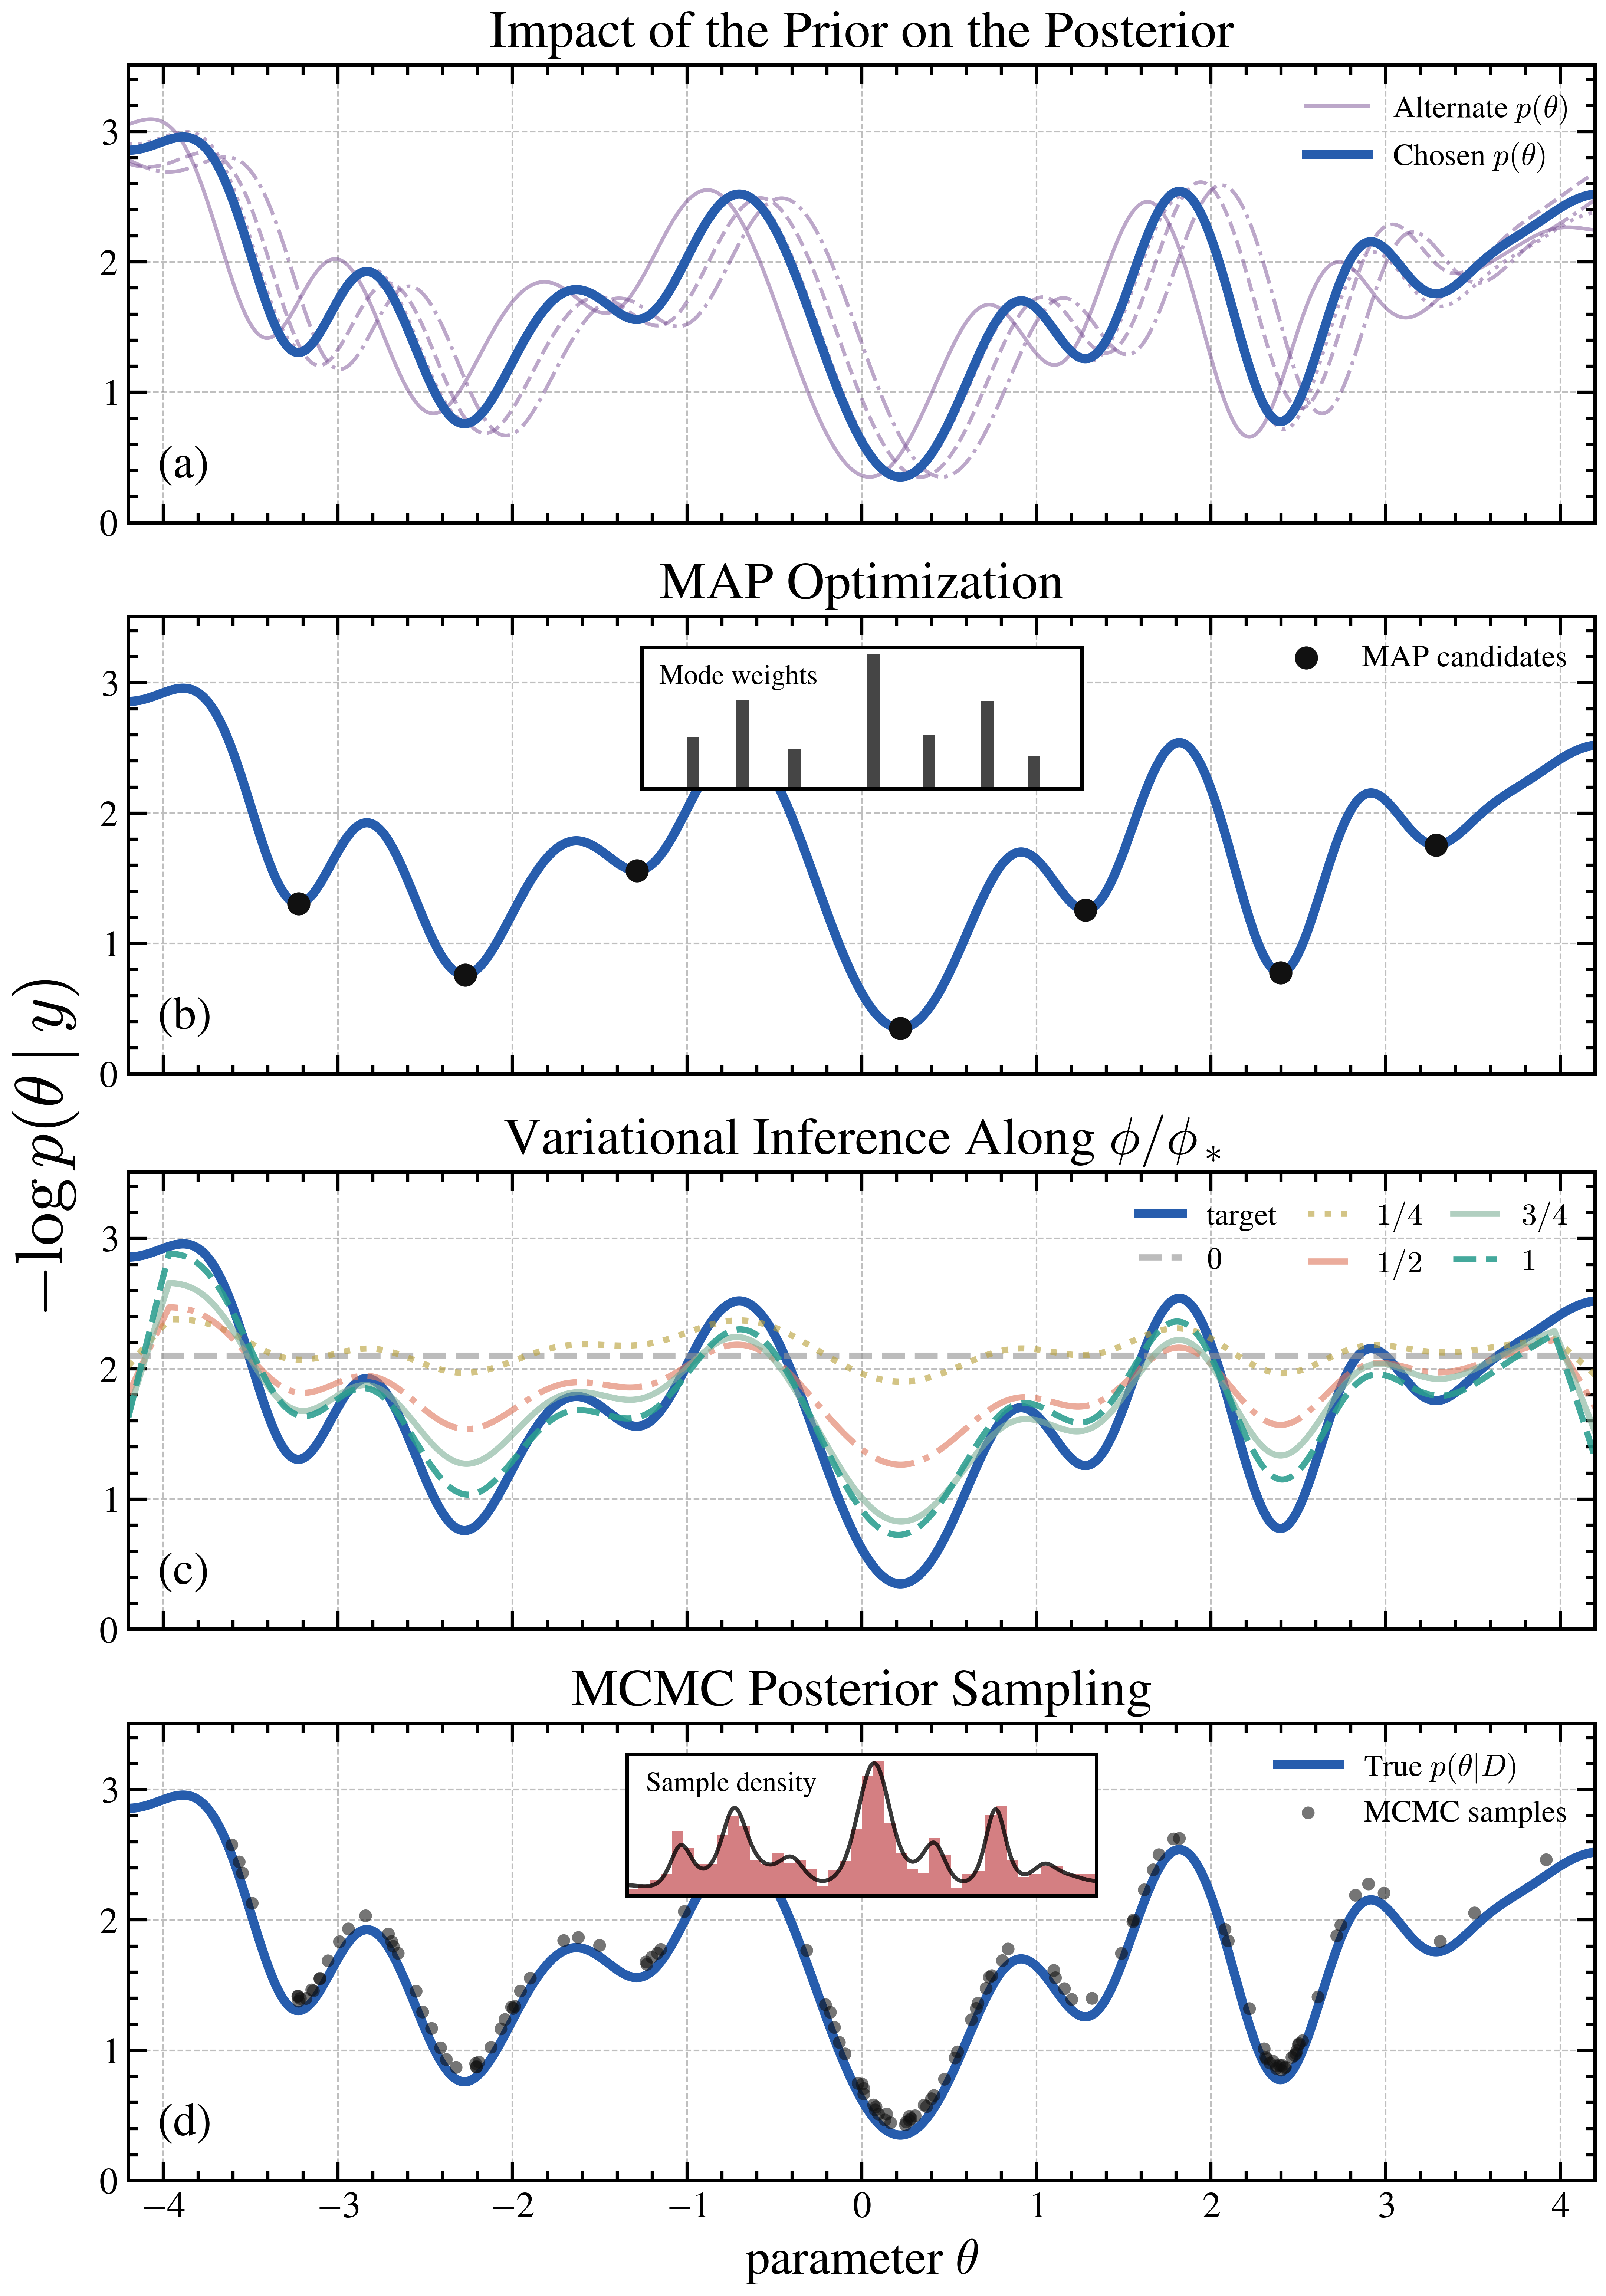

Saved /mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-extraction/plots/ch3_map_vi_mcmc_visualization.png
Saved /mnt/ufs18/rs-021/ascsn/aaron-philip/barrier-extraction/plots/ch3_map_vi_mcmc_visualization.pdf


In [10]:
main_color = "#275DAD"
alt_color = "#7A5195"
map_color = "#111111"
vi_colors = ["0.58", "#B8A03A", "#E07A5F", "#81B29A", "#2A9D8F"]
mcmc_color = "#C44E52"

fig, axes = plt.subplots(4, 1, figsize=(7.2, 10.3), sharex=True, layout="constrained")
fig.supylabel(r"$-\log p(\theta\mid y)$", fontsize=22)

for ax in axes:
    ax.set_xlim(theta.min(), theta.max())
    ax.set_ylim(0.0, loss.max() + 0.55)
    ax.grid(True, alpha=0.25)

# Prior sensitivity / posterior landscape.
ax = axes[0]
for j, variant in enumerate(prior_variant_losses):
    ax.plot(theta, variant, color=alt_color, lw=1.2, alpha=0.5, label=r"Alternate $p(\theta)$" if j == 0 else None)
ax.plot(theta, loss, color=main_color, lw=3.0, label=r"Chosen $p(\theta)$")
ax.set_title("Impact of the Prior on the Posterior")
ax.legend(frameon=False, loc="upper right")
ax.text(0.02, 0.10, "(a)", transform=ax.transAxes, fontsize=15)

# MAP: local optima are point estimates.
ax = axes[1]
ax.plot(theta, loss, color=main_color, lw=3.0)
ax.scatter(min_theta, min_loss, s=42, color=map_color, zorder=5, label="MAP candidates")
ax.set_title("MAP Optimization")
ax.legend(frameon=False, loc="upper right")
ax.text(0.02, 0.10, "(b)", transform=ax.transAxes, fontsize=15)

axins = inset_axes(ax, width="30%", height="31%", loc="upper center", borderpad=1.0)
axins.bar(min_theta, min_weight, width=0.24, color=map_color, alpha=0.78)
axins.set_xlim(theta.min(), theta.max())
axins.set_ylim(0, 1.05)
axins.set_xticks([])
axins.set_yticks([])
axins.text(0.04, 0.88, "Mode weights", transform=axins.transAxes, ha="left", va="top", fontsize=9)

# Variational inference: a restricted family is optimized toward the posterior.
ax = axes[2]
ax.plot(theta, loss, color=main_color, lw=3.0, label="target")
for (progress, curve, label), color in zip(vi_curves, vi_colors):
    ax.plot(theta, curve, color=color, lw=2.0, alpha=0.62 if progress < 1.0 else 0.88, label=label)
ax.set_title(r"Variational Inference Along $\phi/\phi_*$")
legend = ax.legend(
    frameon=False,
    ncol=3,
    loc="upper right",
    columnspacing=1.0,
    handlelength=1.4,
)
legend._legend_box.align = "left"
ax.text(0.02, 0.10, "(c)", transform=ax.transAxes, fontsize=15)

# MCMC: samples populate the posterior mass rather than just minima.
ax = axes[3]
ax.plot(theta, loss, color=main_color, lw=3.0, label=r"True $p(\theta|D)$")
ax.scatter(mcmc_theta, mcmc_loss, s=17, color=map_color, alpha=0.58, edgecolor="none", label="MCMC samples", zorder=5)
ax.set_title("MCMC Posterior Sampling")
ax.set_xlabel(r"parameter $\theta$")
ax.legend(frameon=False, loc="upper right")
ax.text(0.02, 0.10, "(d)", transform=ax.transAxes, fontsize=15)

axins = inset_axes(ax, width="32%", height="31%", loc="upper center", borderpad=1.0)
axins.hist(mcmc_hist_theta, bins=42, density=True, color=mcmc_color, alpha=0.72)
axins.plot(theta, posterior, color="black", lw=1.3, alpha=0.78)
axins.set_xlim(theta.min(), theta.max())
axins.set_xticks([])
axins.set_yticks([])
axins.text(0.04, 0.88, "Sample density", transform=axins.transAxes, ha="left", va="top", fontsize=9)

out_png = PLOT_DIR / "ch3_map_vi_mcmc_visualization.png"
out_pdf = PLOT_DIR / "ch3_map_vi_mcmc_visualization.pdf"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
fig.savefig(out_pdf, bbox_inches="tight")
plt.show()

print(f"Saved {out_png}")
print(f"Saved {out_pdf}")
